In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
path = kagglehub.dataset_download(
    "zeynepustun/e-commerce-customer-segmentation-dataset"
)

files_found = glob.glob(path + "/**/*.csv", recursive=True)

Using Colab cache for faster access to the 'e-commerce-customer-segmentation-dataset' dataset.


In [ ]:
df = pd.read_csv(files_found[0])

print(df.head())
print(df.shape)

   customer_id  age  annual_income_k$  spending_score  membership_years  \
0         1001   23                30              80               1.2   
1         1002   45                75              20               5.8   
2         1003   34                60              55               3.1   
3         1004   25                45              70               2.5   
4         1005   56                85              15               7.0   

  segment  
0    High  
1     Low  
2  Medium  
3    High  
4     Low  
(20, 6)


In [ ]:
df = df.drop_duplicates()
df = df.dropna()

In [ ]:
print(df.isnull().sum())
print(df.shape)

customer_id         0
age                 0
annual_income_k$    0
spending_score      0
membership_years    0
segment             0
dtype: int64
(20, 6)


In [ ]:
X = df[['age', 'annual_income_k$', 'spending_score',
        'membership_years']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

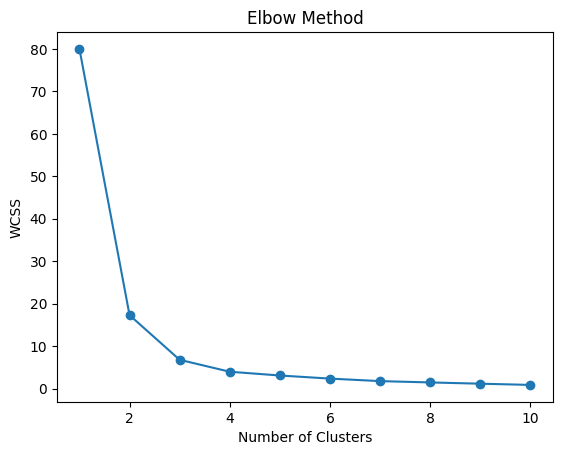

In [ ]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

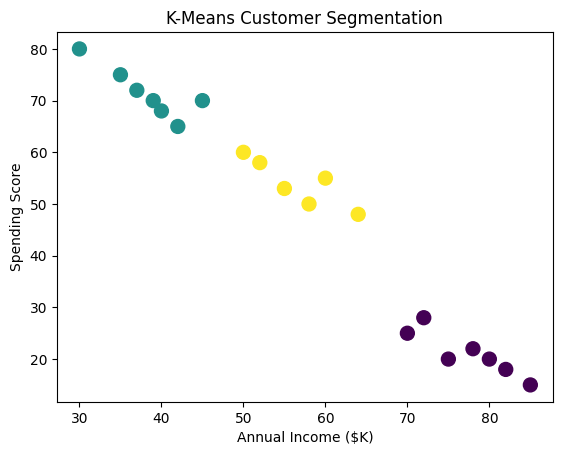

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

plt.scatter(df['annual_income_k$'], df['spending_score'],
            c=df['KMeans_Cluster'], s=100)
plt.xlabel("Annual Income ($K)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation")
plt.show()

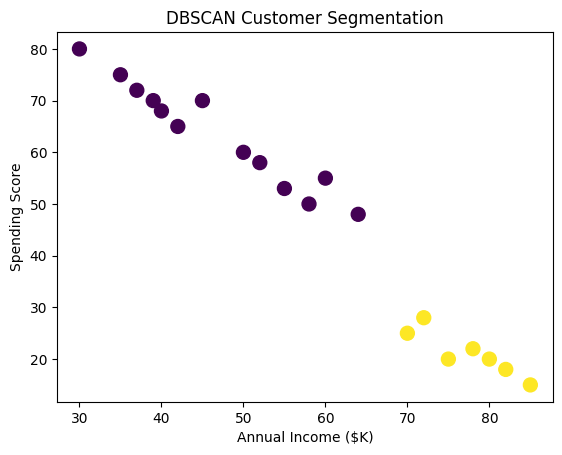

DBSCAN_Cluster
0    13
1     7
Name: count, dtype: int64


In [ ]:
dbscan = DBSCAN(eps=1.2, min_samples=3)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

plt.scatter(df['annual_income_k$'], df['spending_score'],
            c=df['DBSCAN_Cluster'], s=100)
plt.xlabel("Annual Income ($K)")
plt.ylabel("Spending Score")
plt.title("DBSCAN Customer Segmentation")
plt.show()

print(df['DBSCAN_Cluster'].value_counts())

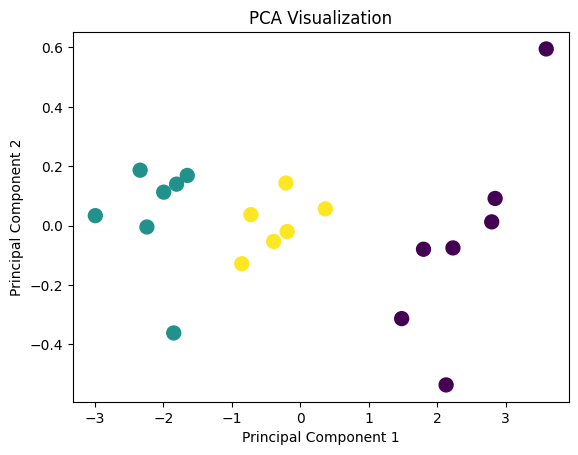

Variance retained: 99.13 %


In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=df['KMeans_Cluster'], s=100)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.show()

print("Variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

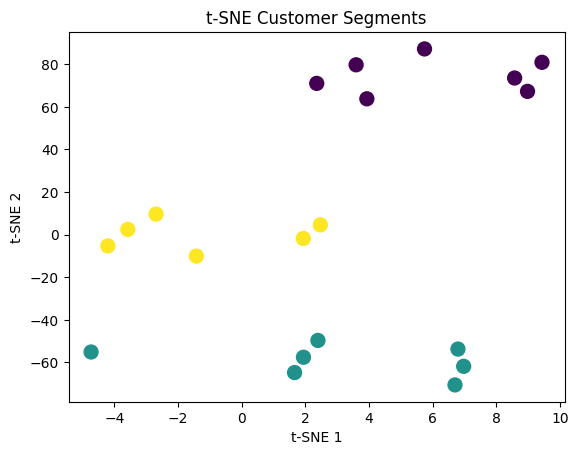

In [ ]:
tsne = TSNE(n_components=2, random_state=42,
            perplexity=5, init='random',
            learning_rate='auto')

X_tsne = tsne.fit_transform(X_scaled)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=df['KMeans_Cluster'], s=100)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE Customer Segments")
plt.show()

In [ ]:
summary = df.groupby('KMeans_Cluster')[
    ['age', 'annual_income_k$', 'spending_score',
     'membership_years']
].mean().round(2)

display(summary)

for cluster, row in summary.iterrows():
    if row['annual_income_k$'] >= 60 and row['spending_score'] >= 60:
        persona = "Potential High-Value Customers"
        strategy = "Loyalty rewards and premium offers"
    elif row['spending_score'] >= 60:
        persona = "High-Spending Customers"
        strategy = "Cross-selling and product recommendations"
    elif row['annual_income_k$'] >= 60:
        persona = "High-Income, Low-Spending Customers"
        strategy = "Personalized offers"
    else:
        persona = "Moderate or Low-Spending Customers"
        strategy = "Targeted promotions"

    print(f"Cluster {cluster}: {persona} — {strategy}")

,age,annual_income_k$,spending_score,membership_years
KMeans_Cluster,,,,
0,46.00,77.43,21.14,6.09
1,26.86,38.29,71.43,1.96
2,34.50,56.50,54.00,3.48


Cluster 0: High-Income, Low-Spending Customers — Personalized offers
Cluster 1: High-Spending Customers — Cross-selling and product recommendations
Cluster 2: Moderate or Low-Spending Customers — Targeted promotions


In [ ]:
print("K-Means cluster counts:")
print(df['KMeans_Cluster'].value_counts().sort_index())

K-Means cluster counts:
KMeans_Cluster
0    7
1    7
2    6
Name: count, dtype: int64


In [ ]:
print("\nDBSCAN cluster counts:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())


DBSCAN cluster counts:
DBSCAN_Cluster
0    13
1     7
Name: count, dtype: int64


In [ ]:
print("\nDBSCAN noise points:",
      (df['DBSCAN_Cluster'] == -1).sum())


DBSCAN noise points: 0


In [ ]:
df.to_csv("customer_segmentation_results.csv", index=False)

In [ ]:
from google.colab import files
files.download("customer_segmentation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>